Name: Mingze Geng  

Github Username: Mingze88

USC ID: 1418612987




## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download Data

Package imports

In [211]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
pd.set_option('display.precision', 5)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})
RANDOM_SEED = 552

In [ ]:
series_names = [
    'avg_rss12', 'var_rss12',
    'avg_rss13', 'var_rss13',
    'avg_rss23', 'var_rss23'
]
activities = [
    'bending1', 'bending2', 'cycling', 'lying',
    'sitting', 'standing', 'walking'
]
expected_counts = dict(zip(activities, [7, 6, 15, 15, 15, 15, 15]))

# Find the relative data folder from common Jupyter working directories.
candidates = [
    Path('../data'), Path('../data/AReM'),
    Path('data'), Path('data/AReM'), Path('AReM'), Path('.')
]
def csv_count(folder):
    return sum(len(list((folder / activity).glob('dataset*.csv')))
               for activity in activities)

existing = [folder for folder in candidates
            if any((folder / activity).is_dir() for activity in activities)]
if not existing:
    raise FileNotFoundError(
        f'Could not find activity folders from {Path.cwd()}. '
        'Expected data/<activity>/datasetN.csv or data/AReM/<activity>/datasetN.csv.'
    )
DATA_DIR = max(existing, key=csv_count)

recordings = {}
audit = []
for activity in activities:
    files = sorted((DATA_DIR / activity).glob('dataset*.csv'),
                   key=lambda p: int(re.search(r'dataset(\d+)', p.name).group(1)))
    if len(files) != expected_counts[activity]:
        counts = {name: len(list((DATA_DIR / name).glob('dataset*.csv')))
                  for name in activities}
        raise ValueError(
            f'Data folder {DATA_DIR} has the wrong number of CSV files: {counts}. '
            'Check that all 88 recording files are present.'
        )

    for path in files:
        number = int(re.search(r'dataset(\d+)', path.name).group(1))
        rows = []
        for line in path.read_text(encoding='utf-8-sig').splitlines():
            line = line.strip().rstrip(',')
            if not line or line.startswith('#'):
                continue
            rows.append(re.split(r'[,\s]+', line))

        values = np.asarray(rows, dtype=float)
        if values.ndim != 2 or values.shape[1] != 7:
            raise ValueError(f'Unexpected data format in {path}')
        if not np.isfinite(values).all():
            raise ValueError(f'Nonfinite value in {path}')

        timestamps = values[:, 0]
        if len(np.unique(timestamps)) != len(timestamps):
            raise ValueError(f'Duplicate timestamps in {path}')
        if not np.all(np.diff(timestamps) > 0):
            raise ValueError(f'Timestamps are not increasing in {path}')

        recordings[(activity, number)] = pd.DataFrame(
            values[:, 1:], columns=series_names
        )
        missing = sorted(set(range(0, 120000, 250)) - set(timestamps))
        audit.append({
            'activity': activity,
            'dataset': number,
            'rows': len(values),
            'missing_timestamps_ms': missing
        })

assert len(recordings) == 88
for activity, count in expected_counts.items():
    found = {number for act, number in recordings if act == activity}
    assert found == set(range(1, count + 1)), (
        f'{activity}: expected dataset numbers 1 through {count}, found {sorted(found)}'
    )

audit_df = pd.DataFrame(audit).sort_values(['activity', 'dataset'])
display(audit_df.groupby('activity').agg(
    instances=('dataset', 'size'),
    min_rows=('rows', 'min'),
    max_rows=('rows', 'max')
))
display(audit_df.loc[audit_df['rows'] != 480])
print(f'Validated {len(recordings)} recordings from {DATA_DIR}.')

### (b) Test and Train Data

In [214]:
def is_test(activity, number):
    return number <= (2 if activity in ['bending1', 'bending2'] else 3)

split_rows = [{'activity': a, 'dataset': n,
               'split': 'test' if is_test(a, n) else 'train'}
              for a, n in recordings]
split_df = pd.DataFrame(split_rows).sort_values(['activity', 'dataset'])
split_summary = pd.crosstab(split_df['activity'], split_df['split'])
display(split_summary[['train', 'test']])
assert (split_df['split'] == 'train').sum() == 69
assert (split_df['split'] == 'test').sum() == 19
train_keys = {(a, n) for a, n in recordings if not is_test(a, n)}
test_keys = set(recordings) - train_keys
assert train_keys.isdisjoint(test_keys)

split,train,test
activity,,
bending1,5,2
bending2,4,2
cycling,12,3
lying,12,3
sitting,12,3
standing,12,3
walking,12,3


### (c) Feature Extraction

#### i. Research

| Type | Common features | What they describe |
|---|---|---|
| Location | Mean, median, quantiles | Typical signal level |
| Extremes | Minimum, maximum, range | Bounds and amplitude span |
| Dispersion | Standard deviation, variance, interquartile range | Variation in signal values |
| Distribution shape | Skewness, kurtosis | Asymmetry and tail behavior |
| Magnitude | Root mean square, sum of squares (energy) | Signal magnitude |
| Temporal changes | Mean absolute successive difference, linear trend, threshold crossings, peak count | Changes and movement over time |
| Dependence and complexity | Autocorrelation at specified lags, sample entropy | Repetition, dependence, and irregularity |



#### ii. Extraction

In [219]:
statistics = ['min', 'max', 'mean', 'median', 'std', 'q1', 'q3']
feature_columns = [f'{stat}{j}' for j in range(1, 7) for stat in statistics]

def extract_features(frame):
    result = {}
    for j, name in enumerate(series_names, start=1):
        x = frame[name].to_numpy()
        values = [np.min(x), np.max(x), np.mean(x), np.median(x),
                  np.std(x, ddof=1),
                  np.quantile(x, 0.25, method='linear'),
                  np.quantile(x, 0.75, method='linear')]
        result.update({f'{s}{j}': v for s, v in zip(statistics, values)})
    return result

records = []
for instance, ((activity, number), frame) in enumerate(
        sorted(recordings.items()), start=1):
    records.append({'instance': instance, 'activity': activity,
                    'dataset': number,
                    'split': 'test' if is_test(activity, number) else 'train',
                    **extract_features(frame)})
features = pd.DataFrame(records)
X = features.set_index('instance')[feature_columns]
train_features = features.loc[features['split'] == 'train'].copy()
test_features = features.loc[features['split'] == 'test'].copy()
assert X.shape == (88, 42)
assert np.isfinite(X.to_numpy()).all()

display(Markdown('**All 88 instances × 42 extracted features:**'))
display(X)
display(Markdown('**Sample metadata and feature values:**'))
display(features.head())
print('42 = 7 statistics × 6 sensor series; timestamp is not a predictor.')

**All 88 instances × 42 extracted features:**

,min1,max1,mean1,median1,std1,q11,q31,min2,max2,mean2,median2,std2,q12,q32,min3,max3,mean3,median3,std3,q13,q33,min4,max4,mean4,median4,std4,q14,q34,min5,max5,mean5,median5,std5,q15,q35,min6,max6,mean6,median6,std6,q16,q36
instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.62479,40.500,1.47697,39.2500,42.0000,0.0,1.30,0.35860,0.430,0.32260,0.0000,0.5000,4.00,29.50,19.04094,19.250,4.46295,16.0000,23.2500,0.0,7.23,0.83254,0.500,0.96566,0.0000,1.1200,27.25,38.25,34.31129,35.000,2.18845,33.0000,36.0000,0.00,1.92,0.57058,0.430,0.58292,0.0000,1.3000
2,38.00,45.67,42.81281,42.500,1.43555,42.0000,43.6700,0.0,1.22,0.37244,0.470,0.28916,0.0000,0.5000,2.00,29.50,20.09698,21.000,3.89374,19.0000,22.2500,0.0,5.76,0.87644,0.500,1.04726,0.0000,1.1450,27.67,38.50,33.02458,33.000,1.99525,32.0000,34.5000,0.00,3.11,0.57108,0.430,0.60101,0.0000,1.3000
3,35.00,47.40,43.95450,44.330,1.55884,43.0000,45.0000,0.0,1.70,0.42625,0.470,0.33869,0.0000,0.5000,6.50,29.75,22.12235,23.000,3.03094,19.7500,24.0000,0.0,4.44,0.49731,0.430,0.55066,0.0000,0.8300,29.00,38.50,35.58846,36.000,1.99960,35.3625,36.5000,0.00,1.79,0.49329,0.430,0.51351,0.0000,0.9400
4,33.00,47.75,42.17981,43.500,3.67067,39.1500,45.0000,0.0,3.00,0.69604,0.500,0.63086,0.0000,1.1200,8.50,30.00,22.18362,23.000,3.81047,20.5000,24.3725,0.0,5.15,0.98992,0.830,0.95373,0.4300,1.3000,20.00,38.67,33.49392,35.000,3.84945,30.4575,36.3300,0.00,2.18,0.61352,0.500,0.52432,0.0000,1.0000
5,33.00,45.75,41.67806,41.750,2.24349,41.3300,42.7500,0.0,2.83,0.53598,0.500,0.40547,0.4300,0.7100,3.00,28.25,19.00656,19.125,4.08711,16.5000,22.0625,0.0,6.42,0.84188,0.500,0.92880,0.4300,1.1200,23.67,37.50,29.85708,30.000,2.41103,28.4575,31.2500,0.00,1.79,0.38329,0.430,0.38916,0.0000,0.5000
6,37.00,48.00,43.45496,43.250,1.38610,42.5000,45.0000,0.0,1.58,0.37808,0.470,0.31557,0.0000,0.5000,5.75,27.00,15.79333,15.000,3.84764,13.0000,18.2700,0.0,10.03,0.84935,0.500,0.99576,0.4300,1.1200,8.00,33.50,23.03479,23.500,2.48886,22.2500,24.0000,0.00,5.26,0.67965,0.500,0.62253,0.4300,0.8700
7,36.25,48.00,43.96912,44.500,1.61836,43.3100,44.6700,0.0,1.50,0.41312,0.470,0.26311,0.4300,0.5000,1.50,26.33,15.86802,16.250,3.74242,14.2500,18.0000,0.0,5.17,0.66635,0.470,0.78898,0.0000,0.9400,11.33,30.75,22.10375,21.670,3.31830,20.5000,23.7500,0.00,2.96,0.55531,0.490,0.48783,0.0000,0.8300
8,12.75,51.00,24.56296,24.250,3.73751,23.1875,26.5000,0.0,6.87,0.59083,0.430,0.83741,0.0000,0.7100,0.00,25.33,19.12133,20.250,4.29961,18.0000,22.0000,0.0,6.76,0.73677,0.470,0.92705,0.0000,0.8700,10.67,30.00,23.49304,23.750,3.69379,20.5000,27.0000,0.00,4.97,0.70019,0.500,0.69372,0.4300,0.8700
9,0.00,42.75,27.46460,28.000,3.58358,25.5000,30.0000,0.0,7.76,0.44971,0.430,0.76720,0.0000,0.5000,7.50,35.00,20.84254,20.750,3.82627,18.0000,22.5000,0.0,5.76,0.77992,0.500,0.90444,0.0000,0.9400,0.00,33.00,17.61794,18.000,5.05364,15.0000,20.7500,0.00,6.76,1.12213,0.830,1.01234,0.4700,1.3000


**Sample metadata and feature values:**

,instance,activity,dataset,split,min1,max1,mean1,median1,std1,q11,q31,min2,max2,mean2,median2,std2,q12,q32,min3,max3,mean3,median3,std3,q13,q33,min4,max4,mean4,median4,std4,q14,q34,min5,max5,mean5,median5,std5,q15,q35,min6,max6,mean6,median6,std6,q16,q36
0,1,bending1,1,test,37.25,45.00,40.62479,40.50,1.47697,39.25,42.00,0.0,1.30,0.35860,0.43,0.32260,0.00,0.50,4.0,29.50,19.04094,19.250,4.46295,16.00,23.2500,0.0,7.23,0.83254,0.50,0.96566,0.00,1.120,27.25,38.25,34.31129,35.0,2.18845,33.0000,36.00,0.0,1.92,0.57058,0.43,0.58292,0.0,1.30
1,2,bending1,2,test,38.00,45.67,42.81281,42.50,1.43555,42.00,43.67,0.0,1.22,0.37244,0.47,0.28916,0.00,0.50,2.0,29.50,20.09698,21.000,3.89374,19.00,22.2500,0.0,5.76,0.87644,0.50,1.04726,0.00,1.145,27.67,38.50,33.02458,33.0,1.99525,32.0000,34.50,0.0,3.11,0.57108,0.43,0.60101,0.0,1.30
2,3,bending1,3,train,35.00,47.40,43.95450,44.33,1.55884,43.00,45.00,0.0,1.70,0.42625,0.47,0.33869,0.00,0.50,6.5,29.75,22.12235,23.000,3.03094,19.75,24.0000,0.0,4.44,0.49731,0.43,0.55066,0.00,0.830,29.00,38.50,35.58846,36.0,1.99960,35.3625,36.50,0.0,1.79,0.49329,0.43,0.51351,0.0,0.94
3,4,bending1,4,train,33.00,47.75,42.17981,43.50,3.67067,39.15,45.00,0.0,3.00,0.69604,0.50,0.63086,0.00,1.12,8.5,30.00,22.18362,23.000,3.81047,20.50,24.3725,0.0,5.15,0.98992,0.83,0.95373,0.43,1.300,20.00,38.67,33.49392,35.0,3.84945,30.4575,36.33,0.0,2.18,0.61352,0.50,0.52432,0.0,1.00
4,5,bending1,5,train,33.00,45.75,41.67806,41.75,2.24349,41.33,42.75,0.0,2.83,0.53598,0.50,0.40547,0.43,0.71,3.0,28.25,19.00656,19.125,4.08711,16.50,22.0625,0.0,6.42,0.84188,0.50,0.92880,0.43,1.120,23.67,37.50,29.85708,30.0,2.41103,28.4575,31.25,0.0,1.79,0.38329,0.43,0.38916,0.0,0.50


42 = 7 statistics × 6 sensor series; timestamp is not a predictor.


#### iii. Standard Deviation

,feature,sample_sd,ci90_lower,ci90_upper
0,min1,9.56998,8.26217,10.76138
1,max1,4.39436,3.32802,5.28492
2,mean1,5.33572,4.70403,5.88636
3,median1,5.44005,4.79028,6.00431
4,std1,1.77215,1.57216,1.95003
5,q11,6.15359,5.58162,6.65241
6,q31,5.13892,4.33194,5.84087
7,min2,0.00000,0.00000,0.00000
8,max2,5.06273,4.62285,5.40217
9,mean2,1.57416,1.39413,1.70685


Percentile bootstrap: 10,000 resamples; seed=552; ddof=1.


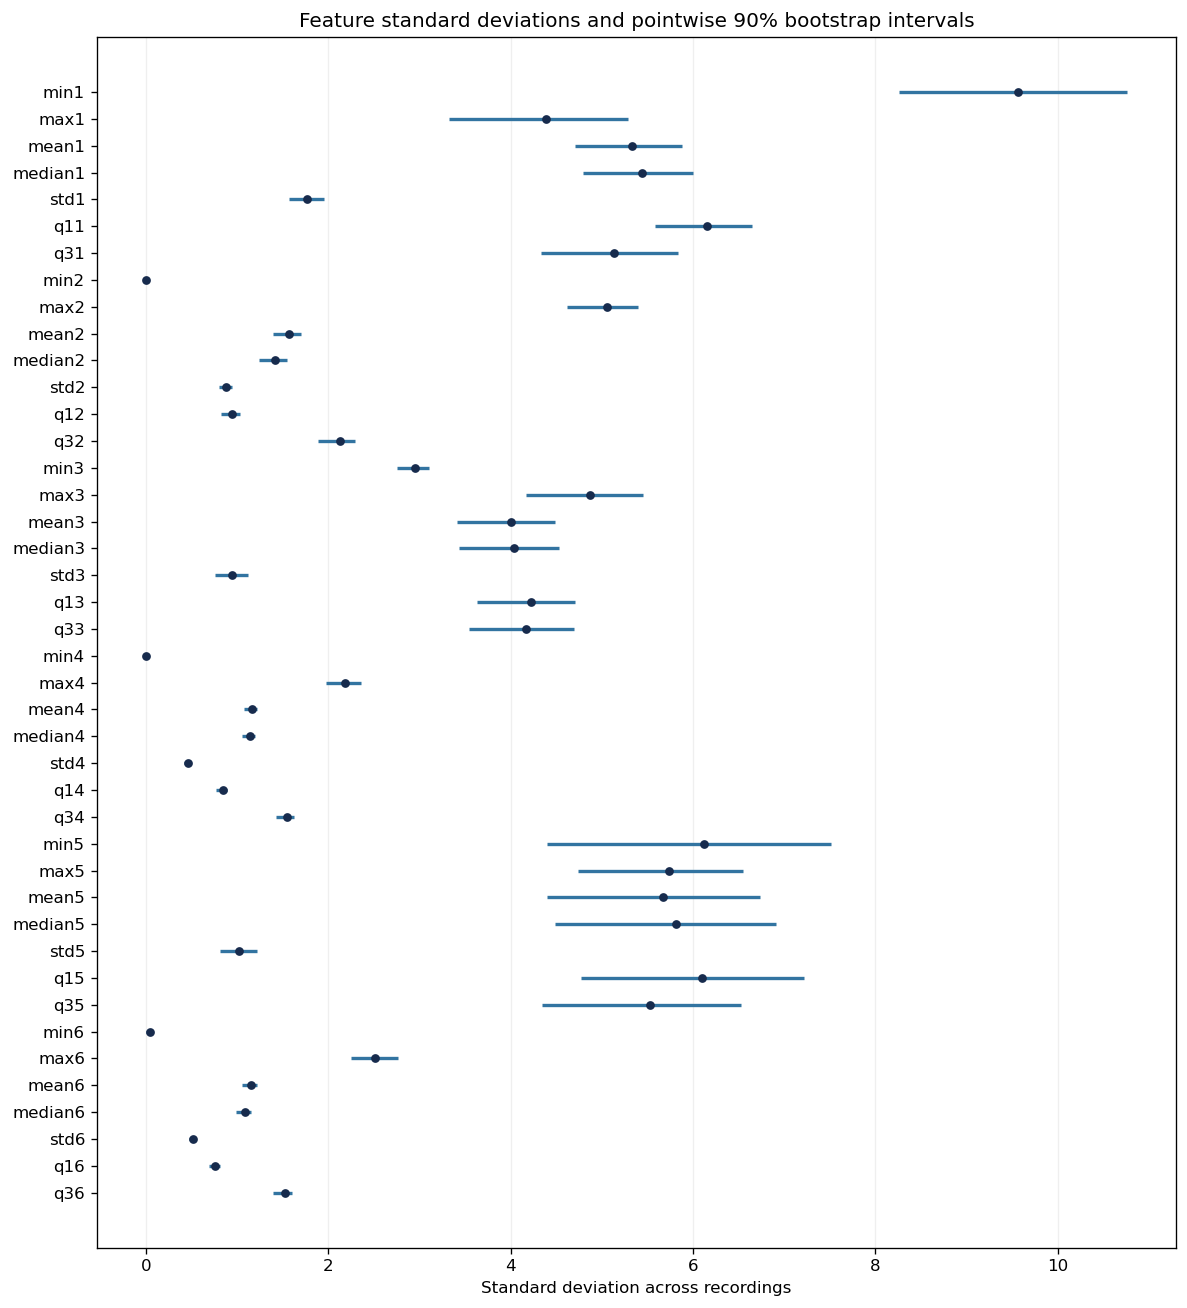

In [221]:
values = X.to_numpy()
n, p = values.shape
feature_sd = np.std(values, axis=0, ddof=1)
B = 10000
rng = np.random.default_rng(RANDOM_SEED)
bootstrap_sd = np.empty((B, p))
batch_size = 250
for start in range(0, B, batch_size):
    stop = min(start + batch_size, B)
    # Resample complete recording rows to preserve relationships among features.
    indices = rng.integers(0, n, size=(stop-start, n))
    bootstrap_sd[start:stop] = np.std(values[indices], axis=1, ddof=1)
lower, upper = np.quantile(bootstrap_sd, [0.05, 0.95], axis=0)
sd_ci = pd.DataFrame({'feature': feature_columns,
                      'sample_sd': feature_sd,
                      'ci90_lower': lower,
                      'ci90_upper': upper})
assert len(sd_ci) == 42
assert np.all(lower <= upper)
display(sd_ci)
print(f'Percentile bootstrap: {B:,} resamples; seed={RANDOM_SEED}; ddof=1.')

fig, ax = plt.subplots(figsize=(10, 11))
y = np.arange(p)
ax.hlines(y, lower, upper, color='#3274a1', linewidth=2)
ax.scatter(feature_sd, y, color='#172b4d', s=18, zorder=3)
ax.set_yticks(y, feature_columns)
ax.invert_yaxis()
ax.set_xlabel('Standard deviation across recordings')
ax.set_title('Feature standard deviations and pointwise 90% bootstrap intervals')
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
plt.show()

For each feature, I calculate the sample standard deviation across the 88 recordings. For each of 10,000 bootstrap samples, I draw 88 recordings with replacement and recalculate all 42 standard deviations.

The 5th and 95th percentiles of the bootstrap results give a pointwise 90% confidence interval for each feature’s standard deviation. I resample whole recordings, not individual time points. This treats the recordings as independent draws from the pooled activity data.

These intervals describe uncertainty in each feature’s standard deviation. They do not show where 90% of individual feature values fall. They are not simultaneous confidence intervals for all 42 features.

I use all 88 recordings for this descriptive calculation. I do not use these results to fit or tune a classifier on the held-out test set.

#### iv. Select Features

1. Mean summarizes the typical RSS level. Sensor position and body posture can change that level.
2. Standard deviation captures variation during the activity. It may help distinguish steady postures from repeated movement.
3. Maximum captures a high signal level. It may show an extreme change that the mean does not capture.

These features describe the signal’s level, variation, and extremes. Some features, such as the mean and median, may provide similar information. The maximum can be sensitive to outliers, so a later model should assess its usefulness with training data only. A feature’s large standard deviation across recordings does not prove that it is important. Features can use different scales.


## 2. ISLR 3.7.4

### (a) Linear Train

The cubic model’s training RSS will be less than or equal to the linear model’s training RSS. The cubic model includes the linear model as a special case. We can set $\beta_2=\beta_3=0$ to get the linear model. So, the cubic model’s best fit cannot have a higher RSS. The two RSS values can be equal.



### (b) Linear Test

We expect the linear model to have lower test RSS. The linear model matches the true relationship. The cubic model adds terms that may fit noise in the training data and increase prediction variance. One particular test set may give a different result.



### (c) Not Linear Train

The cubic model’s training RSS will be less than or equal to the linear model’s. The cubic model still includes the linear model as a special case. So, its best training fit cannot be worse. 


### (d) Not Linear Testing

There is not enough information to know which model will have lower test RSS. A cubic model may perform better if it captures the relationship’s curvature. A linear model may perform better if the nonlinearity is small or the cubic model overfits. The result depends on the shape of the relationship and the amount of noise.
